# Sesión 02 — Modelos de Clasificación
## Ejercicio 3 — Dataset propio: clima de Bengaluru
**Ingeniería del Conocimiento (ISO56B)** · UNCP · 2026-II

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

**Dataset:** Clima histórico de Bengaluru, India (datos horarios 2009–2020 → 4018 días, 11 features, clasificación binaria: ¿día lluvioso?)

> **Enunciado:** Seleccione un dataset de clasificación de Kaggle/UCI (mín. 500 registros, 5 features). Aplique los 4 modelos + al menos 1 adicional (Random Forest, Gradient Boosting o Naive Bayes). Documente métricas, curvas ROC, matriz de selección y justificación del mejor modelo.

---

## 1. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc,
    ConfusionMatrixDisplay, RocCurveDisplay
)

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print('✓ Librerías cargadas correctamente')

✓ Librerías cargadas correctamente


---
## 2. Carga y exploración del dataset

El archivo **`bengaluru.csv`** contiene registros **horarios** del clima de Bengaluru desde el 01/01/2009 hasta el 01/01/2020 (96 432 filas, 25 columnas, sin valores nulos).

**Agregación diaria.** Varias columnas son valores diarios repetidos en las 24 horas (`maxtempC`, `mintempC`, `sunHour`, `uvIndex`), por lo que las filas de un mismo día son casi idénticas. Si se dividiera por hora, casi-copias del mismo día quedarían en train y en test (fuga de información). Por eso se agrega por día: **4018 registros**, con el promedio diario de cada variable y la precipitación total del día.

**Features (11):** `maxtempC`, `mintempC`, `sunHour`, `uvIndex`, `humidity`, `cloudcover`, `pressure`, `DewPointC`, `windspeedKmph`, `WindGustKmph`, `visibility`.
Se excluyen `totalSnow_cm` (siempre 0), las variables astronómicas (salida/puesta del sol y la luna, iluminación lunar), las derivadas de la temperatura (`FeelsLikeC`, `HeatIndexC`, `WindChillC`), `winddirDegree` (es un ángulo) y `precipMM`, que define el target (sería fuga de información).

**Target binario:** **lluvioso (1)** si la precipitación total del día es ≥ 1 mm (umbral habitual en climatología para un "día con lluvia"); **seco (0)** en caso contrario.

In [2]:
# En Colab: subir 'bengaluru.csv' al panel de archivos antes de ejecutar
df_raw = pd.read_csv('bengaluru.csv', parse_dates=['date_time'])

feature_names = ['maxtempC', 'mintempC', 'sunHour', 'uvIndex', 'humidity', 'cloudcover',
                 'pressure', 'DewPointC', 'windspeedKmph', 'WindGustKmph', 'visibility']

# Agregación diaria: promedio de las features y precipitación total del día
df = (df_raw.groupby(df_raw['date_time'].dt.date)
            .agg({**{c: 'mean' for c in feature_names}, 'precipMM': 'sum'})
            .round(2))
df['target'] = (df['precipMM'] >= 1).astype(int)
df['condicion'] = df['target'].map({0: 'seco', 1: 'lluvioso'})

print(f'Dataset horario original: {df_raw.shape[0]} registros')
print(f'Dataset diario: {df.shape[0]} muestras, {len(feature_names)} features')
print(f'\nDistribución de clases:')
print(df['condicion'].value_counts())
print(f'\nProporción: {df["target"].mean():.1%} lluvioso, {1-df["target"].mean():.1%} seco')

Dataset horario original: 96432 registros
Dataset diario: 4018 muestras, 11 features

Distribución de clases:
condicion
seco        2737
lluvioso    1281
Name: count, dtype: int64

Proporción: 31.9% lluvioso, 68.1% seco


In [3]:
df[feature_names + ['precipMM']].describe().round(3)

,maxtempC,mintempC,sunHour,uvIndex,humidity,cloudcover,pressure,DewPointC,windspeedKmph,WindGustKmph,visibility,precipMM
count,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000,4018.000
mean,29.646,19.337,10.653,5.900,64.895,34.848,1010.554,16.086,12.449,17.371,9.275,1.865
std,3.447,2.774,1.987,0.851,15.568,24.072,2.859,3.686,4.993,6.250,1.318,4.367
min,18.000,11.000,4.200,4.000,18.420,0.000,1003.170,-0.210,2.960,4.500,3.250,0.000
25%,27.000,18.000,8.800,5.000,53.250,13.620,1008.330,13.960,8.790,12.880,8.880,0.000
50%,29.000,20.000,11.600,6.000,68.100,32.710,1010.210,17.420,11.540,16.580,9.880,0.100
75%,32.000,21.000,11.600,6.000,76.460,53.240,1012.790,18.750,15.040,20.910,10.000,1.700
max,40.000,28.000,12.900,8.000,98.250,100.000,1018.960,22.120,34.790,46.540,20.000,48.400


---
## 3. Análisis exploratorio orientado a clasificación

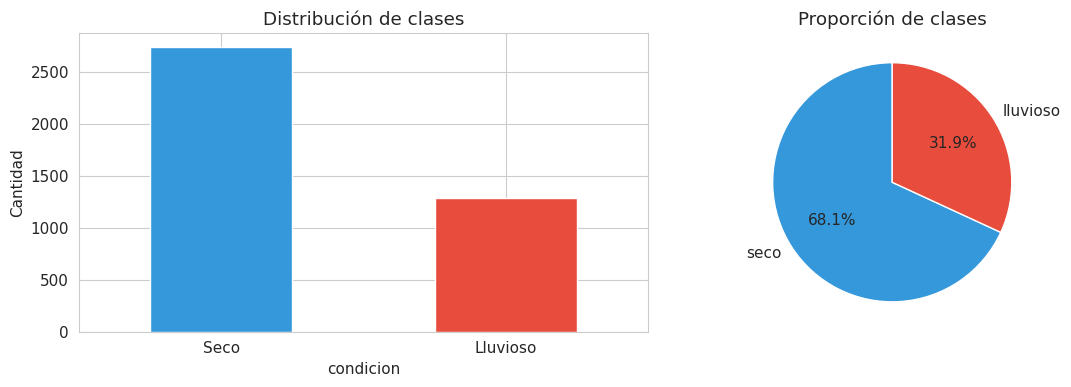

In [4]:
# 3.1  Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Conteo
colors = ['#3498db', '#e74c3c']   # 0 = seco, 1 = lluvioso
df['condicion'].value_counts().plot(kind='bar', ax=axes[0], color=colors)
axes[0].set_title('Distribución de clases')
axes[0].set_ylabel('Cantidad')
axes[0].set_xticklabels(['Seco', 'Lluvioso'], rotation=0)

# Pie chart
df['condicion'].value_counts().plot(kind='pie', ax=axes[1], colors=colors,
    autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

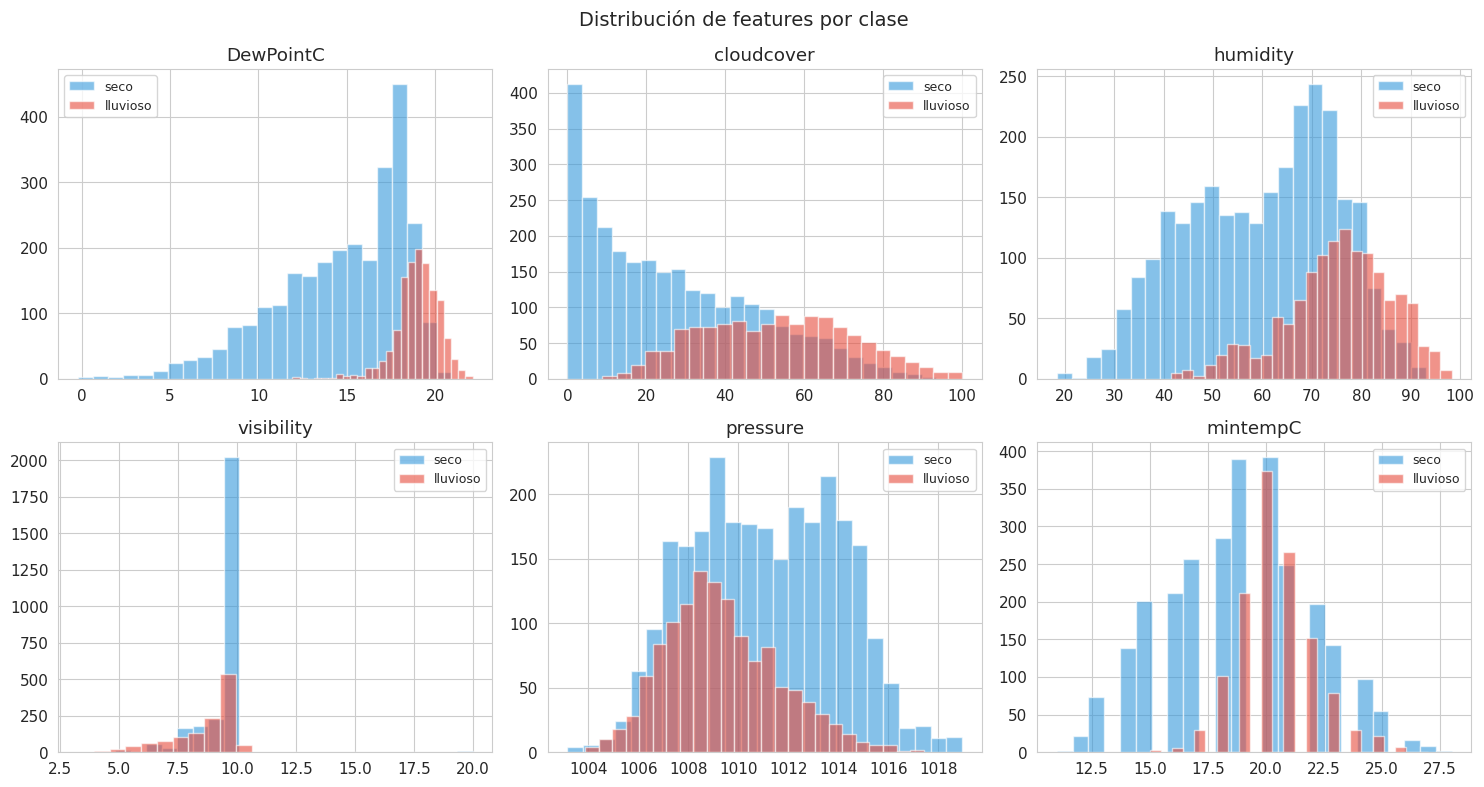

In [5]:
# 3.2  Distribución de features clave por clase
key_features = ['DewPointC', 'cloudcover', 'humidity',
                'visibility', 'pressure', 'mintempC']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, feat in enumerate(key_features):
    ax = axes[i//3, i%3]
    for label, color in zip([0, 1], colors):
        subset = df[df['target'] == label][feat]
        ax.hist(subset, bins=25, alpha=0.6, color=color,
                label='seco' if label == 0 else 'lluvioso')
    ax.set_title(feat)
    ax.legend(fontsize=9)

plt.suptitle('Distribución de features por clase', fontsize=14)
plt.tight_layout()
plt.show()

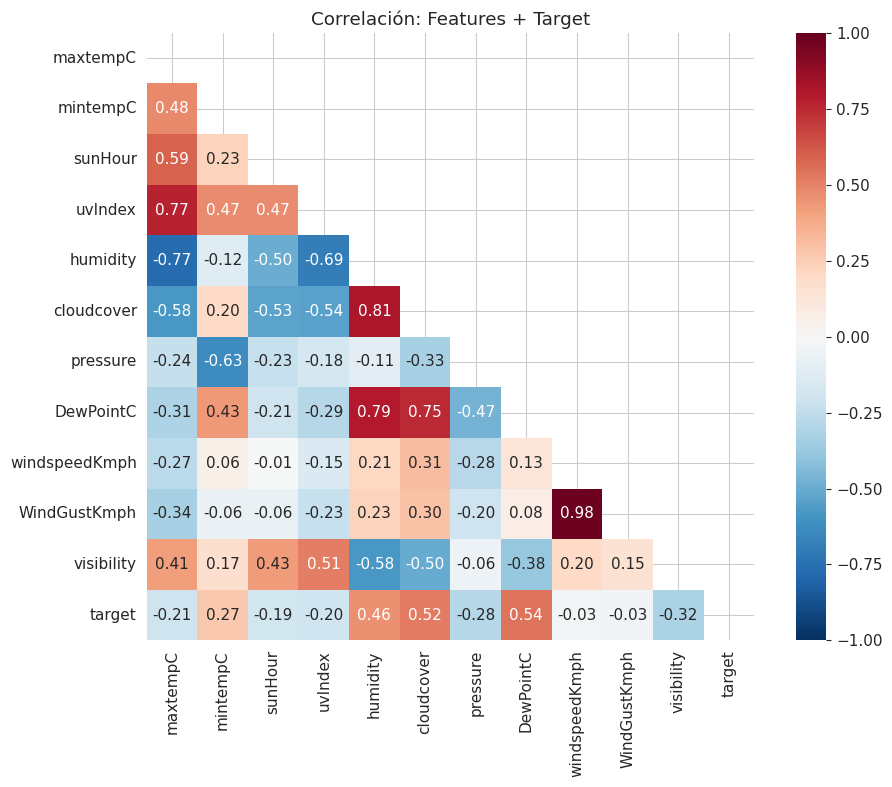

In [6]:
# 3.3  Matriz de correlación (features + target)
plt.figure(figsize=(10, 8))
corr = df[feature_names + ['target']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlación: Features + Target')
plt.tight_layout()
plt.show()

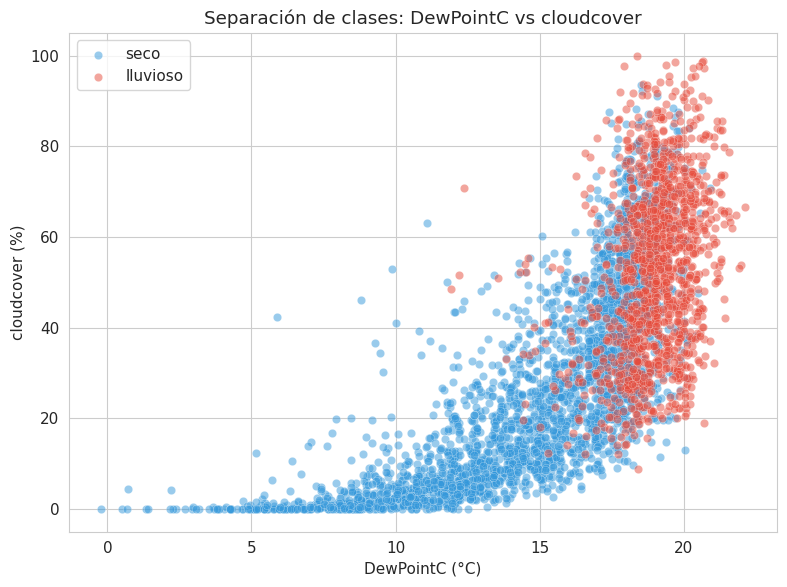

In [7]:
# 3.4  Scatter plot: 2 features más discriminativas
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in zip([0, 1], colors, ['seco', 'lluvioso']):
    mask = df['target'] == label
    ax.scatter(df.loc[mask, 'DewPointC'], df.loc[mask, 'cloudcover'],
              alpha=0.5, c=color, label=name, edgecolors='w', linewidth=0.3)
ax.set_xlabel('DewPointC (°C)')
ax.set_ylabel('cloudcover (%)')
ax.set_title('Separación de clases: DewPointC vs cloudcover')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Preparación de datos

In [8]:
X = df[feature_names].copy()
y = df['target'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Entrenamiento: {X_train.shape[0]} muestras')
print(f'Test:          {X_test.shape[0]} muestras')
print(f'\nProporción en train: {y_train.mean():.1%} lluvioso')
print(f'Proporción en test:  {y_test.mean():.1%} lluvioso')

# Stratified K-Fold para validación cruzada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Entrenamiento: 3214 muestras
Test:          804 muestras

Proporción en train: 31.9% lluvioso
Proporción en test:  31.8% lluvioso


### Funciones auxiliares para evaluación de clasificadores

In [9]:
def eval_classifier(model, X_tr, y_tr, X_te, y_te, model_name='Modelo'):
    """Evalúa un clasificador: métricas, matriz de confusión y reporte."""
    y_pred = model.predict(X_te)

    metrics = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred),
        'F1-Score':  f1_score(y_te, y_pred)
    }

    print(f'=== {model_name} ===')
    for k, v in metrics.items():
        print(f'  {k}: {v:.4f}')

    # Matriz de confusión
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Seco', 'Lluvioso'],
                yticklabels=['Seco', 'Lluvioso'])
    axes[0].set_title(f'Matriz de Confusión — {model_name}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Real')

    # Desglose FP y FN
    tn, fp, fn, tp = cm.ravel()
    labels = ['TN\n(seco\ncorrecto)', 'FP\n(seco→\nlluvioso)',
              'FN\n(lluvioso→\nseco)', 'TP\n(lluvioso\ncorrecto)']
    values = [tn, fp, fn, tp]
    bar_colors = ['#2ecc71', '#f39c12', '#e74c3c', '#3498db']
    axes[1].bar(labels, values, color=bar_colors)
    axes[1].set_title(f'Desglose — {model_name}')
    axes[1].set_ylabel('Cantidad')

    plt.tight_layout()
    plt.show()

    print(f'\n  FN (día lluvioso no detectado): {fn}')
    print(f'  FP (día seco como lluvioso):    {fp}')
    print(f'\nReporte completo:')
    print(classification_report(y_te, y_pred,
          target_names=['seco', 'lluvioso']))

    return metrics


def plot_roc(model, X_te, y_te, model_name='Modelo', ax=None):
    """Genera la curva ROC de un modelo."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_te)
    else:
        print(f'{model_name}: no soporta probabilidades')
        return None

    fpr, tpr, _ = roc_curve(y_te, y_score)
    roc_auc = auc(fpr, tpr)

    ax.plot(fpr, tpr, linewidth=2,
            label=f'{model_name} (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
    ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    ax.set_title(f'Curva ROC — {model_name}')
    ax.legend()

    return roc_auc

---
## 5. Modelo 1 — Regresión Logística

**Fundamento:** Modelo lineal que estima P(y=1|x) mediante la función sigmoide σ(z) = 1/(1+e^(−z)). La frontera de decisión es lineal en el espacio de features. Se optimiza minimizando la Log-Loss (entropía cruzada binaria) con regularización L2 por defecto.

In [10]:
# 5.1  Pipeline con estandarización
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Validación cruzada estratificada
cv_lr = cross_validate(pipe_lr, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Regresión Logística — Cross-Validation (5-fold)')
print(f'  Accuracy:  {cv_lr["test_accuracy"].mean():.4f} ± {cv_lr["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_lr["test_f1"].mean():.4f} ± {cv_lr["test_f1"].std():.4f}')
print(f'  Recall:    {cv_lr["test_recall"].mean():.4f} ± {cv_lr["test_recall"].std():.4f}')

# Entrenar modelo final
pipe_lr.fit(X_train, y_train)
y_pred_lr = pipe_lr.predict(X_test)

Regresión Logística — Cross-Validation (5-fold)
  Accuracy:  0.8335 ± 0.0135
  F1-Score:  0.7320 ± 0.0291
  Recall:    0.7161 ± 0.0513


=== Regresión Logística ===
  Accuracy: 0.8358
  Precision: 0.7562
  Recall: 0.7148
  F1-Score: 0.7349


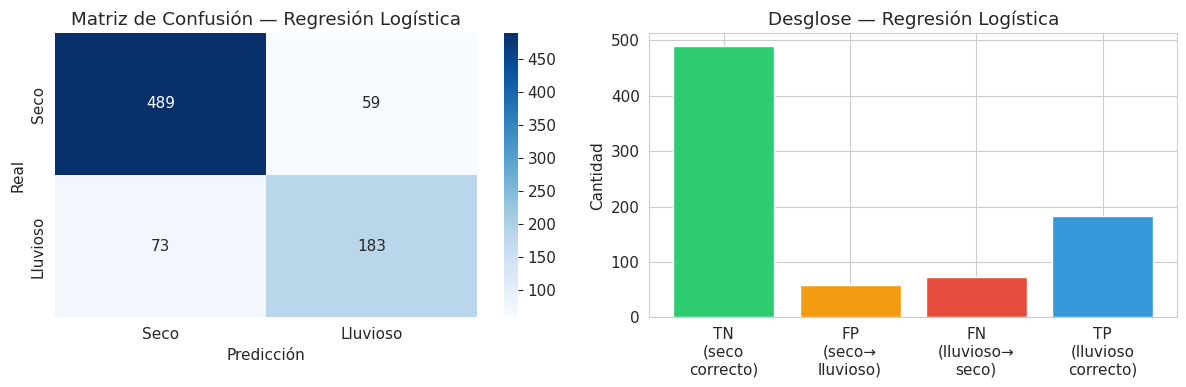


  FN (día lluvioso no detectado): 73
  FP (día seco como lluvioso):    59

Reporte completo:


              precision    recall  f1-score   support

        seco       0.87      0.89      0.88       548
    lluvioso       0.76      0.71      0.73       256

    accuracy                           0.84       804
   macro avg       0.81      0.80      0.81       804
weighted avg       0.83      0.84      0.83       804



In [11]:
# 5.2  Evaluación completa
metrics_lr = eval_classifier(pipe_lr, X_train, y_train, X_test, y_test,
                             'Regresión Logística')

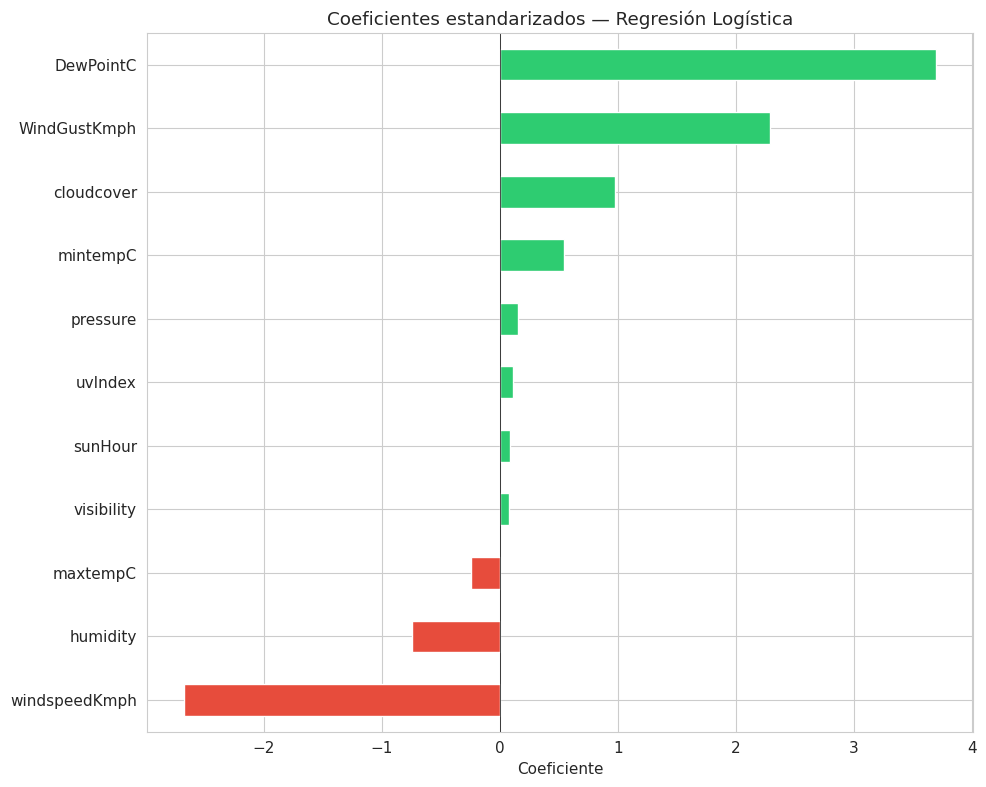

Interpretación:
  → Features que más indican SECO: ['windspeedKmph', 'humidity', 'maxtempC']
  → Features que más indican LLUVIOSO: ['cloudcover', 'WindGustKmph', 'DewPointC']


In [12]:
# 5.3  Coeficientes estandarizados
coefs = pd.Series(
    pipe_lr.named_steps['clf'].coef_[0],
    index=feature_names
).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors_bar = ['#e74c3c' if c < 0 else '#2ecc71' for c in coefs]
coefs.plot(kind='barh', ax=ax, color=colors_bar)
ax.set_title('Coeficientes estandarizados — Regresión Logística')
ax.set_xlabel('Coeficiente')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

print('Interpretación:')
print(f'  → Features que más indican SECO: {coefs.head(3).index.tolist()}')
print(f'  → Features que más indican LLUVIOSO: {coefs.tail(3).index.tolist()}')

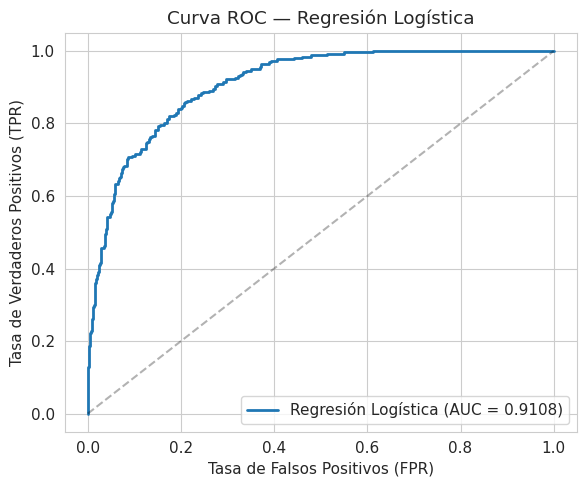

AUC: 0.9108


In [13]:
# 5.4  Curva ROC
fig, ax = plt.subplots(figsize=(6, 5))
auc_lr = plot_roc(pipe_lr, X_test, y_test, 'Regresión Logística', ax)
plt.tight_layout()
plt.show()
print(f'AUC: {auc_lr:.4f}')

---
## 6. Modelo 2 — Árbol de Decisión

**Fundamento:** CART construye particiones recursivas del espacio de features. En cada nodo selecciona la feature y el umbral que maximizan la reducción de impureza (Gini: G(t) = 1 − Σpₖ²). Las particiones son ortogonales a los ejes.

In [14]:
# 6.1  Árbol sin restricciones (para mostrar sobreajuste)
pipe_dt_full = Pipeline([
    ('clf', DecisionTreeClassifier(random_state=42))
])

cv_dt_full = cross_validate(pipe_dt_full, X_train, y_train, cv=skf,
                            scoring=['accuracy', 'f1', 'recall'],
                            return_train_score=True)

print('Árbol de Decisión (SIN restricciones) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt_full["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt_full["test_accuracy"].mean():.4f} ± {cv_dt_full["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt_full["test_f1"].mean():.4f} ± {cv_dt_full["test_f1"].std():.4f}')
print(f'\n⚠ Train accuracy ~1.0 indica sobreajuste')

Árbol de Decisión (SIN restricciones) — CV 5-fold
  Train Accuracy: 1.0000
  Test Accuracy:  0.8311 ± 0.0165
  Test F1-Score:  0.7382 ± 0.0238

⚠ Train accuracy ~1.0 indica sobreajuste


In [15]:
# 6.2  Árbol con pre-poda
pipe_dt = Pipeline([
    ('clf', DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

cv_dt = cross_validate(pipe_dt, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Árbol de Decisión (con pre-poda) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt["test_accuracy"].mean():.4f} ± {cv_dt["test_accuracy"].std():.4f}')
print(f'  Test F1-Score:  {cv_dt["test_f1"].mean():.4f} ± {cv_dt["test_f1"].std():.4f}')
print(f'  Test Recall:    {cv_dt["test_recall"].mean():.4f} ± {cv_dt["test_recall"].std():.4f}')

pipe_dt.fit(X_train, y_train)
y_pred_dt = pipe_dt.predict(X_test)

Árbol de Decisión (con pre-poda) — CV 5-fold
  Train Accuracy: 0.8783
  Test Accuracy:  0.8491 ± 0.0100
  Test F1-Score:  0.7609 ± 0.0073
  Test Recall:    0.7522 ± 0.0301


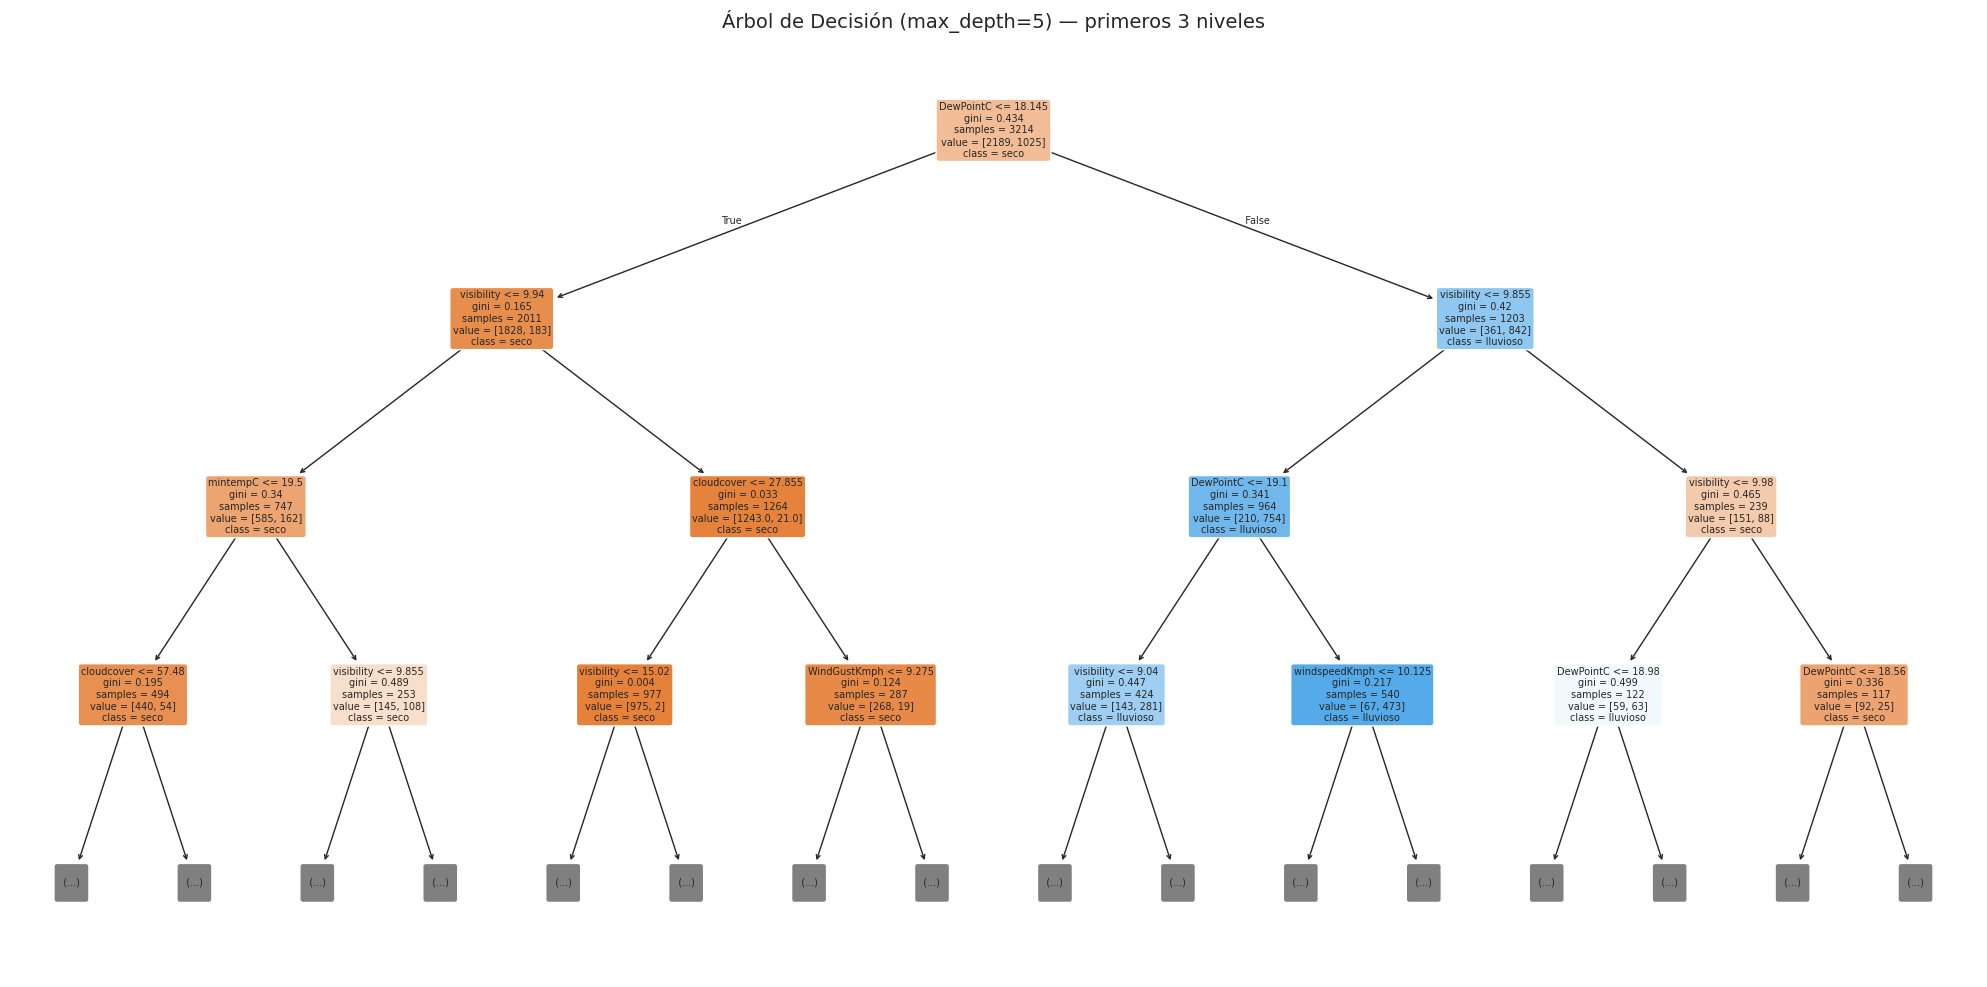

In [16]:
# 6.3  Visualización del árbol podado
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(pipe_dt.named_steps['clf'],
          feature_names=feature_names,
          class_names=['seco', 'lluvioso'],
          filled=True, rounded=True, fontsize=7, ax=ax, max_depth=3)
ax.set_title('Árbol de Decisión (max_depth=5) — primeros 3 niveles', fontsize=14)
plt.tight_layout()
plt.show()

=== Árbol de Decisión ===
  Accuracy: 0.8470
  Precision: 0.7509
  Recall: 0.7773
  F1-Score: 0.7639


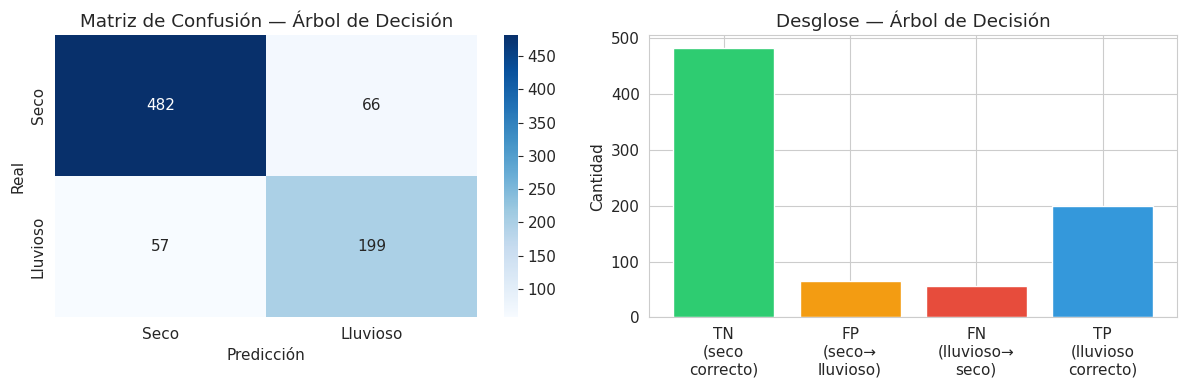


  FN (día lluvioso no detectado): 57
  FP (día seco como lluvioso):    66

Reporte completo:
              precision    recall  f1-score   support

        seco       0.89      0.88      0.89       548
    lluvioso       0.75      0.78      0.76       256

    accuracy                           0.85       804
   macro avg       0.82      0.83      0.83       804
weighted avg       0.85      0.85      0.85       804



In [17]:
# 6.4  Evaluación completa
metrics_dt = eval_classifier(pipe_dt, X_train, y_train, X_test, y_test,
                             'Árbol de Decisión')

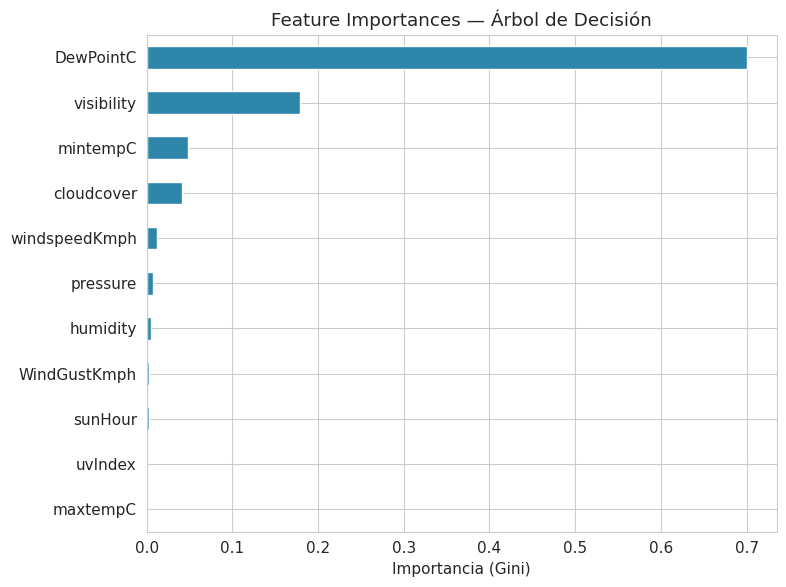

In [18]:
# 6.5  Importancia de features
importances = pd.Series(
    pipe_dt.named_steps['clf'].feature_importances_,
    index=feature_names
).sort_values(ascending=True)

top_imp = importances   # solo hay 11 features
fig, ax = plt.subplots(figsize=(8, 6))
top_imp.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Feature Importances — Árbol de Decisión')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

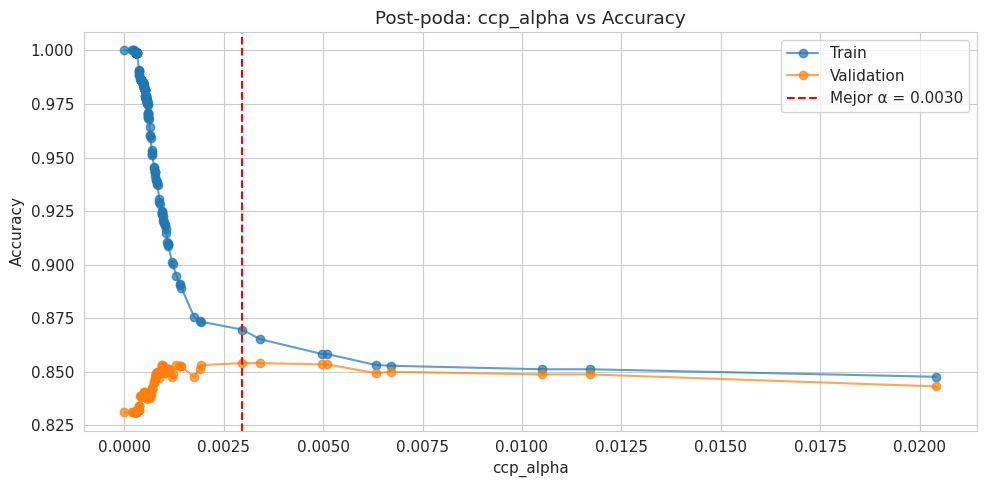

Mejor ccp_alpha: 0.002965


In [19]:
# 6.6  Post-poda con ccp_alpha
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]  # excluir el último (árbol trivial)

train_scores, test_scores = [], []
for alpha in alphas:
    dt_temp = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    cv_temp = cross_validate(dt_temp, X_train, y_train, cv=skf,
                             scoring='accuracy', return_train_score=True)
    train_scores.append(cv_temp['train_score'].mean())
    test_scores.append(cv_temp['test_score'].mean())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(alphas, train_scores, 'o-', label='Train', alpha=0.7)
ax.plot(alphas, test_scores, 'o-', label='Validation', alpha=0.7)
best_idx = np.argmax(test_scores)
ax.axvline(x=alphas[best_idx], color='red', linestyle='--',
           label=f'Mejor α = {alphas[best_idx]:.4f}')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('Accuracy')
ax.set_title('Post-poda: ccp_alpha vs Accuracy')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor ccp_alpha: {alphas[best_idx]:.6f}')

---
## 7. Modelo 3 — Support Vector Machine (SVM)

**Fundamento:** SVM busca el hiperplano de máximo margen γ = 2/‖w‖ que separa las clases. Con margen suave, permite violaciones controladas: min ½‖w‖² + C·Σξᵢ. El kernel trick transforma el espacio para manejar no linealidad.

In [20]:
# 7.1  Pipeline SVM con kernel RBF
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])

cv_svm = cross_validate(pipe_svm, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('SVM (RBF, C=1.0) — CV 5-fold')
print(f'  Accuracy:  {cv_svm["test_accuracy"].mean():.4f} ± {cv_svm["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_svm["test_f1"].mean():.4f} ± {cv_svm["test_f1"].std():.4f}')
print(f'  Recall:    {cv_svm["test_recall"].mean():.4f} ± {cv_svm["test_recall"].std():.4f}')

pipe_svm.fit(X_train, y_train)
y_pred_svm = pipe_svm.predict(X_test)

SVM (RBF, C=1.0) — CV 5-fold
  Accuracy:  0.8525 ± 0.0141
  F1-Score:  0.7675 ± 0.0211
  Recall:    0.7629 ± 0.0199


=== SVM (RBF) ===
  Accuracy: 0.8383
  Precision: 0.7540
  Recall: 0.7305
  F1-Score: 0.7421


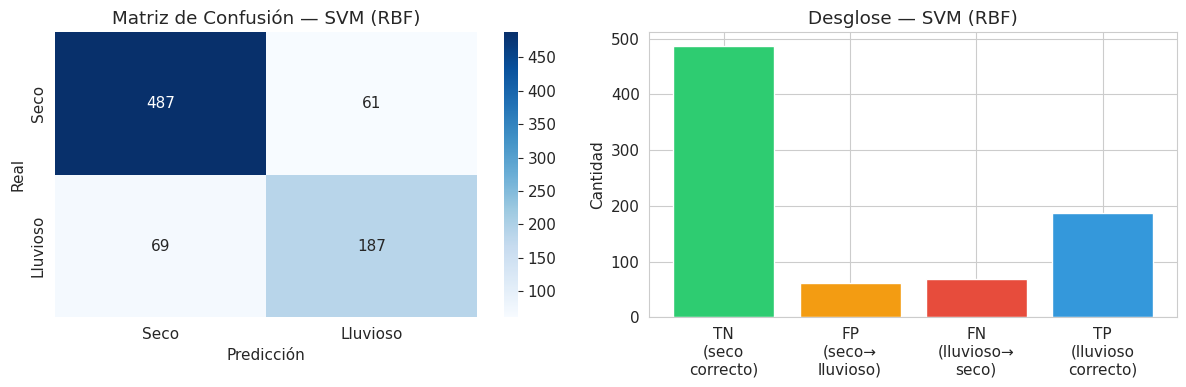


  FN (día lluvioso no detectado): 69
  FP (día seco como lluvioso):    61

Reporte completo:
              precision    recall  f1-score   support

        seco       0.88      0.89      0.88       548
    lluvioso       0.75      0.73      0.74       256

    accuracy                           0.84       804
   macro avg       0.81      0.81      0.81       804
weighted avg       0.84      0.84      0.84       804



In [21]:
# 7.2  Evaluación completa
metrics_svm = eval_classifier(pipe_svm, X_train, y_train, X_test, y_test, 'SVM (RBF)')

  Kernel linear  : Accuracy = 0.8335


  Kernel rbf     : Accuracy = 0.8525


  Kernel poly    : Accuracy = 0.8276


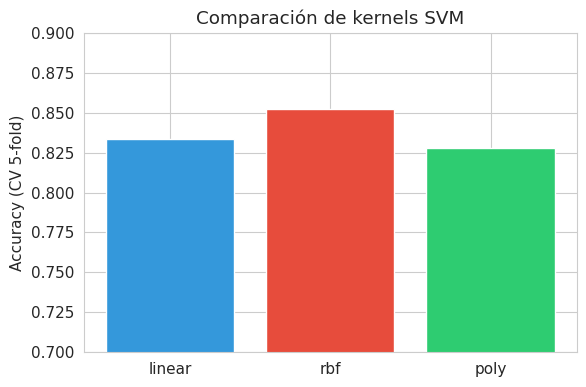

In [22]:
# 7.3  Comparación de kernels
kernels = ['linear', 'rbf', 'poly']
kernel_results = {}

for k in kernels:
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel=k, C=1.0, probability=True, random_state=42))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf,
                          scoring='accuracy')
    kernel_results[k] = cv_k['test_score'].mean()
    print(f'  Kernel {k:8s}: Accuracy = {kernel_results[k]:.4f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(kernel_results.keys(), kernel_results.values(), color=['#3498db', '#e74c3c', '#2ecc71'])
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Comparación de kernels SVM')
ax.set_ylim(0.7, 0.9)
plt.tight_layout()
plt.show()

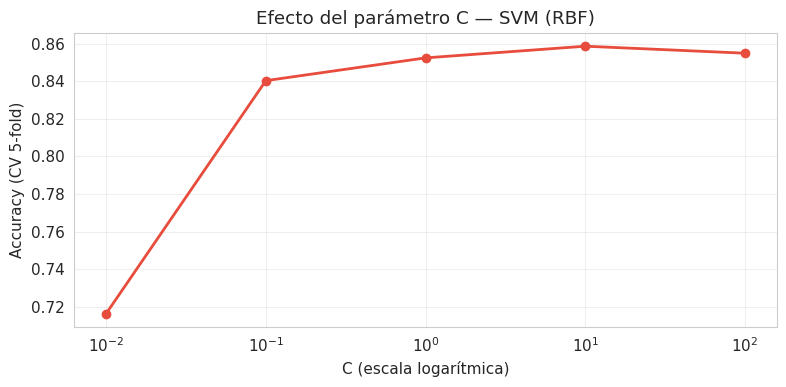


Interpretación:
  C bajo → margen amplio, más errores permitidos (mayor sesgo)
  C alto → margen estrecho, menos errores permitidos (mayor varianza)


In [23]:
# 7.4  Efecto del parámetro C
C_values = [0.01, 0.1, 1, 10, 100]
c_scores = []

for c in C_values:
    pipe_c = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=c, random_state=42))
    ])
    cv_c = cross_validate(pipe_c, X_train, y_train, cv=skf, scoring='accuracy')
    c_scores.append(cv_c['test_score'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(C_values, c_scores, 'o-', color='#e74c3c', linewidth=2)
ax.set_xlabel('C (escala logarítmica)')
ax.set_ylabel('Accuracy (CV 5-fold)')
ax.set_title('Efecto del parámetro C — SVM (RBF)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nInterpretación:')
print('  C bajo → margen amplio, más errores permitidos (mayor sesgo)')
print('  C alto → margen estrecho, menos errores permitidos (mayor varianza)')

---
## 8. Modelo 4 — K-Nearest Neighbors (KNN)

**Fundamento:** Algoritmo de aprendizaje basado en instancias (lazy learning). No construye un modelo explícito; clasifica por voto mayoritario de los K vecinos más cercanos según distancia Euclidiana (por defecto). La regla empírica sugiere K ≈ √n.

In [24]:
# 8.1  Pipeline KNN
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])

cv_knn = cross_validate(pipe_knn, X_train, y_train, cv=skf,
                        scoring=['accuracy', 'f1', 'recall'],
                        return_train_score=True)

print('KNN (K=5) — CV 5-fold')
print(f'  Accuracy:  {cv_knn["test_accuracy"].mean():.4f} ± {cv_knn["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_knn["test_f1"].mean():.4f} ± {cv_knn["test_f1"].std():.4f}')
print(f'  Recall:    {cv_knn["test_recall"].mean():.4f} ± {cv_knn["test_recall"].std():.4f}')

pipe_knn.fit(X_train, y_train)
y_pred_knn = pipe_knn.predict(X_test)

KNN (K=5) — CV 5-fold
  Accuracy:  0.8251 ± 0.0068
  F1-Score:  0.7193 ± 0.0103
  Recall:    0.7024 ± 0.0175


=== KNN (K=5) ===
  Accuracy: 0.8085
  Precision: 0.7143
  Recall: 0.6641
  F1-Score: 0.6883


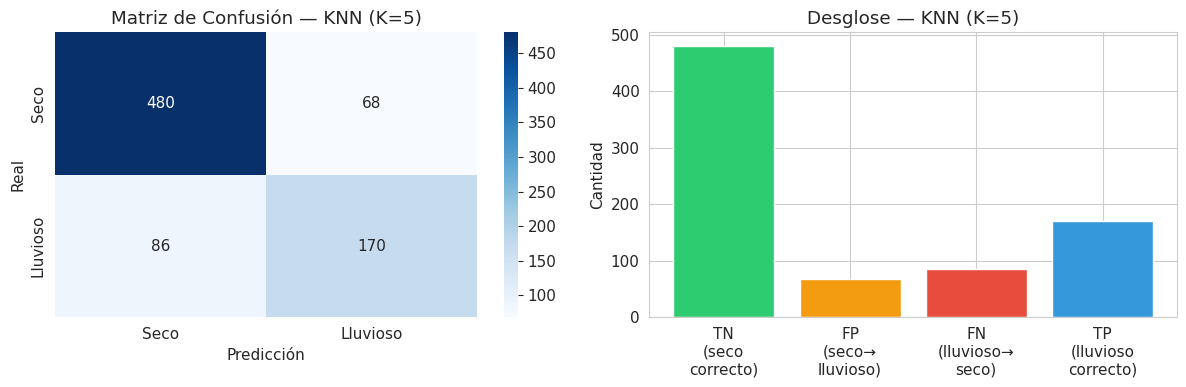


  FN (día lluvioso no detectado): 86
  FP (día seco como lluvioso):    68

Reporte completo:
              precision    recall  f1-score   support

        seco       0.85      0.88      0.86       548
    lluvioso       0.71      0.66      0.69       256

    accuracy                           0.81       804
   macro avg       0.78      0.77      0.78       804
weighted avg       0.81      0.81      0.81       804



In [25]:
# 8.2  Evaluación completa
metrics_knn = eval_classifier(pipe_knn, X_train, y_train, X_test, y_test, 'KNN (K=5)')

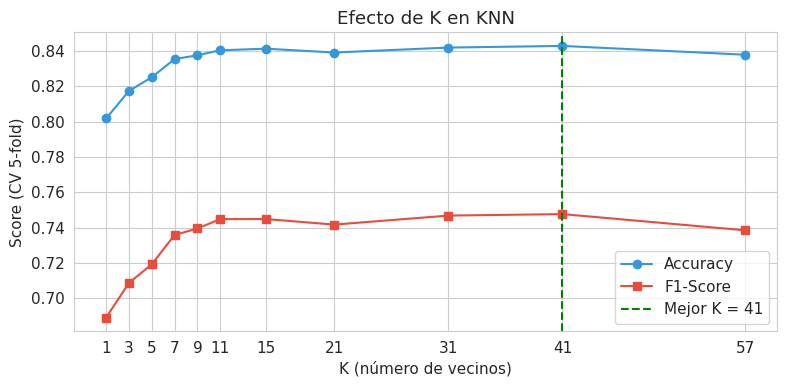

Mejor K por F1: 41
K empírico (√3214): 56


In [26]:
# 8.3  Búsqueda del K óptimo
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 57]   # se añade √n ≈ 57
k_scores_acc = []
k_scores_f1 = []

for k in k_values:
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=k))
    ])
    cv_k = cross_validate(pipe_k, X_train, y_train, cv=skf,
                          scoring=['accuracy', 'f1'])
    k_scores_acc.append(cv_k['test_accuracy'].mean())
    k_scores_f1.append(cv_k['test_f1'].mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, k_scores_acc, 'o-', label='Accuracy', color='#3498db')
ax.plot(k_values, k_scores_f1, 's-', label='F1-Score', color='#e74c3c')
best_k = k_values[np.argmax(k_scores_f1)]
ax.axvline(x=best_k, color='green', linestyle='--', label=f'Mejor K = {best_k}')
ax.set_xlabel('K (número de vecinos)')
ax.set_ylabel('Score (CV 5-fold)')
ax.set_title('Efecto de K en KNN')
ax.legend()
ax.set_xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Mejor K por F1: {best_k}')
print(f'K empírico (√{len(X_train)}): {int(np.sqrt(len(X_train)))}')

In [27]:
# 8.4  Comparación de métricas de distancia
distances = ['euclidean', 'manhattan', 'minkowski']
dist_results = {}

for d in distances:
    p_val = 3 if d == 'minkowski' else 2
    pipe_d = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5, metric=d, p=p_val))
    ])
    cv_d = cross_validate(pipe_d, X_train, y_train, cv=skf, scoring='f1')
    dist_results[d] = cv_d['test_score'].mean()
    label = f'{d} (p={p_val})' if d == 'minkowski' else d
    print(f'  Distancia {label:20s}: F1 = {dist_results[d]:.4f}')

  Distancia euclidean           : F1 = 0.7193


  Distancia manhattan           : F1 = 0.7404


  Distancia minkowski (p=3)     : F1 = 0.7143


---
## 9. Modelo 5 (adicional) — Random Forest

**Fundamento:** Ensamble de muchos árboles de decisión entrenados sobre muestras bootstrap del train y con un subconjunto aleatorio de features en cada división (bagging + aleatoriedad de features). La predicción es el voto mayoritario de los árboles. Promediar árboles poco correlacionados **reduce la varianza** (el sobreajuste) de un árbol individual, a cambio de perder la interpretabilidad de un único árbol.

In [28]:
# 9.1  Pipeline Random Forest
pipe_rf = Pipeline([
    ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                   random_state=42, n_jobs=-1))
])

cv_rf = cross_validate(pipe_rf, X_train, y_train, cv=skf,
                       scoring=['accuracy', 'f1', 'recall'],
                       return_train_score=True)

print('Random Forest (200 árboles) — CV 5-fold')
print(f'  Train Accuracy: {cv_rf["train_accuracy"].mean():.4f}')
print(f'  Accuracy:  {cv_rf["test_accuracy"].mean():.4f} ± {cv_rf["test_accuracy"].std():.4f}')
print(f'  F1-Score:  {cv_rf["test_f1"].mean():.4f} ± {cv_rf["test_f1"].std():.4f}')
print(f'  Recall:    {cv_rf["test_recall"].mean():.4f} ± {cv_rf["test_recall"].std():.4f}')

pipe_rf.fit(X_train, y_train)
y_pred_rf = pipe_rf.predict(X_test)

Random Forest (200 árboles) — CV 5-fold
  Train Accuracy: 0.9401
  Accuracy:  0.8706 ± 0.0082
  F1-Score:  0.7978 ± 0.0102
  Recall:    0.8000 ± 0.0138


=== Random Forest ===
  Accuracy: 0.8619
  Precision: 0.7778
  Recall: 0.7930
  F1-Score: 0.7853


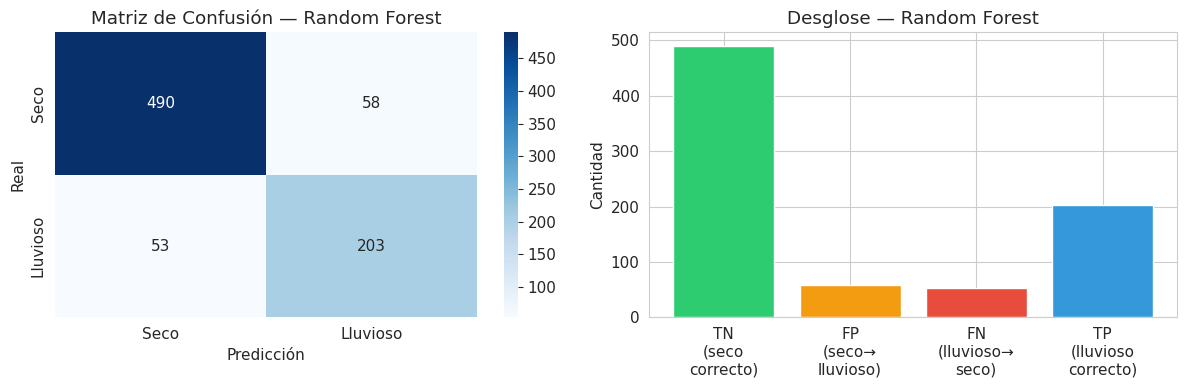


  FN (día lluvioso no detectado): 53
  FP (día seco como lluvioso):    58

Reporte completo:
              precision    recall  f1-score   support

        seco       0.90      0.89      0.90       548
    lluvioso       0.78      0.79      0.79       256

    accuracy                           0.86       804
   macro avg       0.84      0.84      0.84       804
weighted avg       0.86      0.86      0.86       804



In [29]:
# 9.2  Evaluación completa
metrics_rf = eval_classifier(pipe_rf, X_train, y_train, X_test, y_test, 'Random Forest')

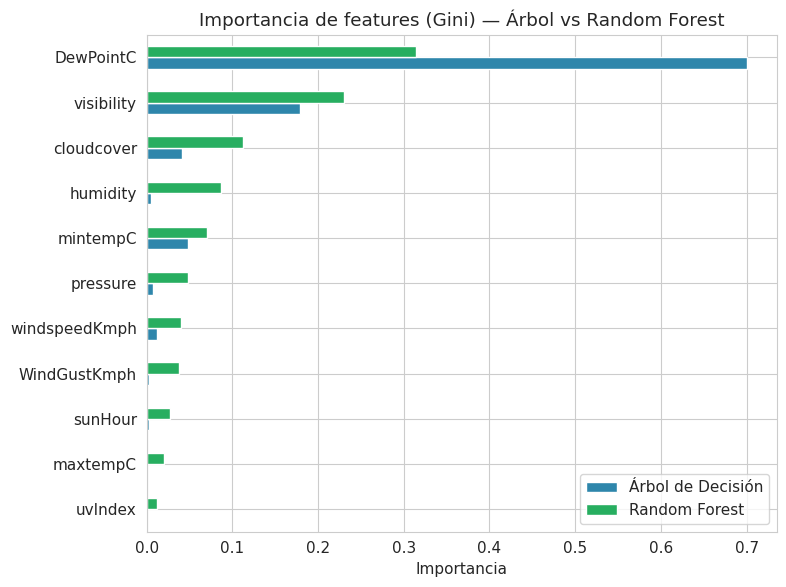

In [30]:
# 9.3  Importancia de features: Random Forest vs Árbol de Decisión
imp_comp = pd.DataFrame({
    'Árbol de Decisión': pipe_dt.named_steps['clf'].feature_importances_,
    'Random Forest': pipe_rf.named_steps['clf'].feature_importances_
}, index=feature_names).sort_values('Random Forest')

imp_comp.plot(kind='barh', figsize=(8, 6), color=['#2E86AB', '#27ae60'])
plt.title('Importancia de features (Gini) — Árbol vs Random Forest')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

---
## 10. Comparación final de modelos

In [31]:
# 10.1  Tabla resumen de métricas
all_models = {
    'Regresión Logística': pipe_lr,
    'Árbol de Decisión': pipe_dt,
    'SVM (RBF)': pipe_svm,
    'KNN (K=5)': pipe_knn,
    'Random Forest': pipe_rf
}

all_metrics = {}
for name, model in all_models.items():
    y_pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc_val = auc(fpr, tpr)
    elif hasattr(model, 'decision_function'):
        y_score = model.decision_function(X_test)
        fpr, tpr, _ = roc_curve(y_test, y_score)
        roc_auc_val = auc(fpr, tpr)
    else:
        roc_auc_val = None

    all_metrics[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC': roc_auc_val
    }

metrics_df = pd.DataFrame(all_metrics).T.round(4)
print('=== Tabla comparativa de métricas (Test Set) ===')
metrics_df

=== Tabla comparativa de métricas (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
Regresión Logística,0.8358,0.7562,0.7148,0.7349,0.9108
Árbol de Decisión,0.8470,0.7509,0.7773,0.7639,0.9198
SVM (RBF),0.8383,0.7540,0.7305,0.7421,0.9137
KNN (K=5),0.8085,0.7143,0.6641,0.6883,0.8725
Random Forest,0.8619,0.7778,0.7930,0.7853,0.9366


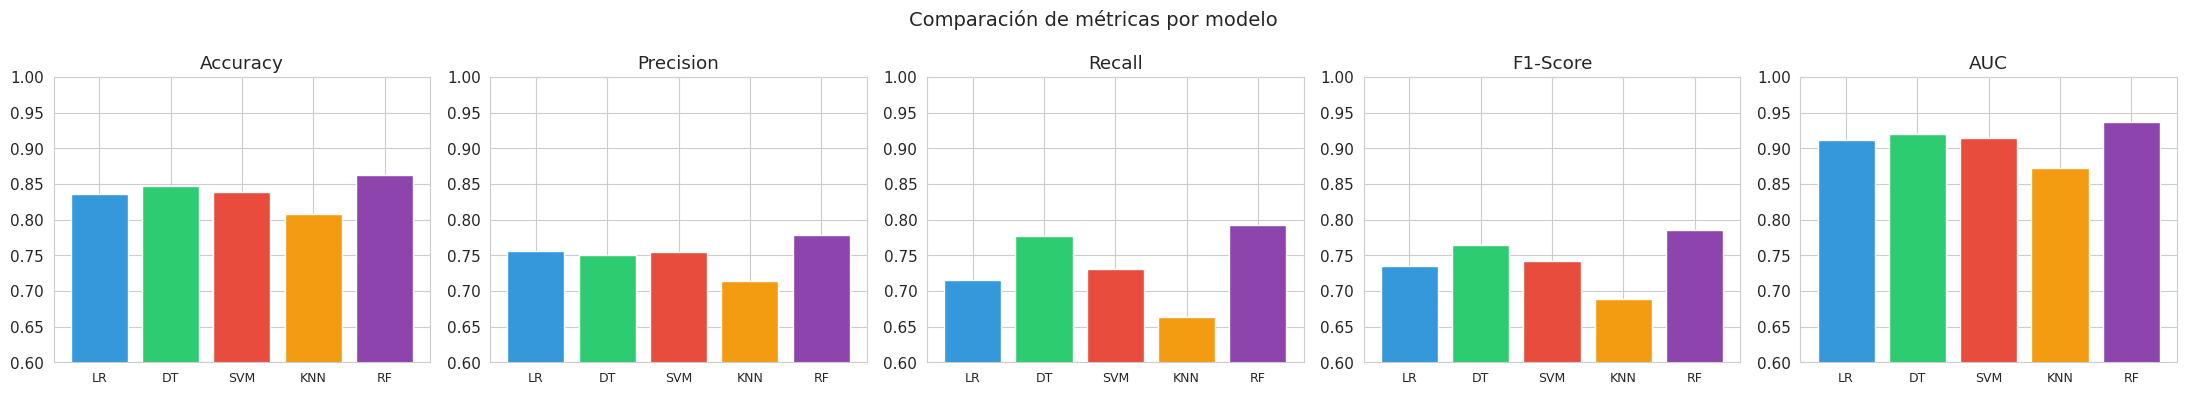

In [32]:
# 10.2  Gráfico de barras comparativo
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
colors_models = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#8e44ad']

for i, metric in enumerate(metric_names):
    values = [all_metrics[m][metric] for m in all_metrics]
    axes[i].bar(range(len(values)), values, color=colors_models)
    axes[i].set_title(metric)
    axes[i].set_ylim(0.6, 1.0)
    axes[i].set_xticks(range(len(values)))
    axes[i].set_xticklabels(['LR', 'DT', 'SVM', 'KNN', 'RF'], fontsize=9)

plt.suptitle('Comparación de métricas por modelo', fontsize=14)
plt.tight_layout()
plt.show()

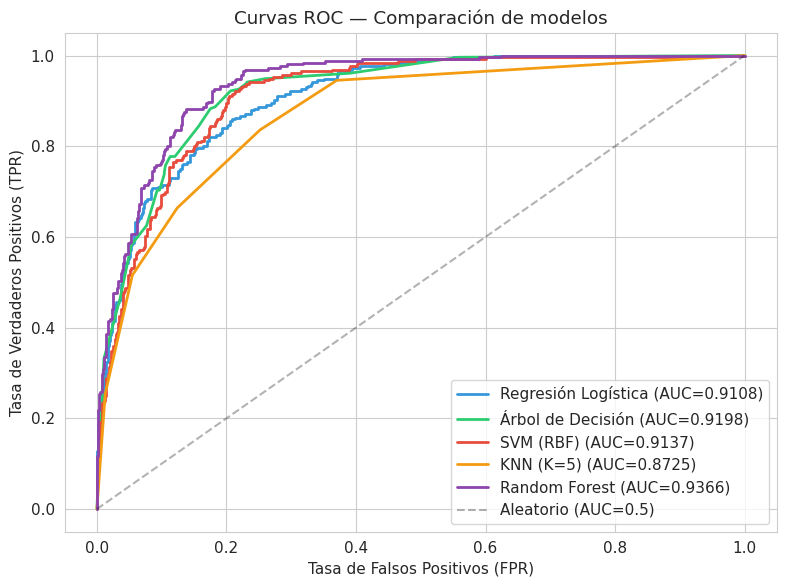

In [33]:
# 10.3  Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(8, 6))

for (name, model), color in zip(all_models.items(), colors_models):
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_prob = model.decision_function(X_test)
    else:
        continue
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, color=color,
            label=f'{name} (AUC={roc_auc_val:.4f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC=0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — Comparación de modelos')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [34]:
# 10.4  Matriz de selección (según los resultados obtenidos en este dataset)
selection_matrix = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Árbol de Decisión', 'SVM (RBF)', 'KNN', 'Random Forest'],
    'F1 test': metrics_df['F1-Score'].values,
    'AUC': metrics_df['AUC'].values,
    'Precisión predictiva': ['★★★☆☆', '★★★★☆', '★★★☆☆', '★★☆☆☆', '★★★★★'],
    'Velocidad (train+pred)': ['★★★★★', '★★★★★', '★★☆☆☆', '★★★★☆', '★★★☆☆'],
    'Interpretabilidad': ['★★★★☆', '★★★★★', '★★☆☆☆', '★★★☆☆', '★★★☆☆'],
    'Escalabilidad': ['★★★★★', '★★★★☆', '★★☆☆☆', '★★☆☆☆', '★★★★☆'],
    'Robustez a outliers': ['★★★☆☆', '★★★★☆', '★★★★☆', '★★☆☆☆', '★★★★★']
}).set_index('Modelo').round(4)

print('=== Matriz de Selección de Modelos — Clima de Bengaluru ===')
selection_matrix

=== Matriz de Selección de Modelos — Clima de Bengaluru ===


,F1 test,AUC,Precisión predictiva,Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Modelo,,,,,,,
Reg. Logística,0.7349,0.9108,★★★☆☆,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,0.7639,0.9198,★★★★☆,★★★★★,★★★★★,★★★★☆,★★★★☆
SVM (RBF),0.7421,0.9137,★★★☆☆,★★☆☆☆,★★☆☆☆,★★☆☆☆,★★★★☆
KNN,0.6883,0.8725,★★☆☆☆,★★★★☆,★★★☆☆,★★☆☆☆,★★☆☆☆
Random Forest,0.7853,0.9366,★★★★★,★★★☆☆,★★★☆☆,★★★★☆,★★★★★


---
## 11. Resumen comparativo y justificación del mejor modelo

**Métricas obtenidas (clase positiva = día lluvioso)**

| Modelo | F1 (CV) | Accuracy test | Precision | Recall | F1 test | AUC | Lluviosos no detectados (FN) | Falsas alarmas (FP) |
|---|---|---|---|---|---|---|---|---|
| Regresión Logística | 0.7320 ± 0.0291 | 0.8358 | 0.7562 | 0.7148 | 0.7349 | 0.9108 | 73 | 59 |
| Árbol de Decisión (pre-poda) | 0.7609 ± 0.0073 | 0.8470 | 0.7509 | 0.7773 | 0.7639 | 0.9198 | 57 | 66 |
| SVM (RBF, C=1) | 0.7675 ± 0.0211 | 0.8383 | 0.7540 | 0.7305 | 0.7421 | 0.9137 | 69 | 61 |
| KNN (K=5) | 0.7193 ± 0.0103 | 0.8085 | 0.7143 | 0.6641 | 0.6883 | 0.8725 | 86 | 68 |
| **Random Forest** | **0.7978 ± 0.0102** | **0.8619** | **0.7778** | **0.7930** | **0.7853** | **0.9366** | **53** | **58** |

| Modelo | Fortalezas (en este dataset) | Limitaciones (en este dataset) |
|---|---|---|
| **Reg. Logística** | Rápida; los coeficientes señalan `DewPointC` y `cloudcover` como los que más indican lluvia | Frontera lineal; los coeficientes de features correlacionadas (`windspeedKmph`/`WindGustKmph`, r ≈ 0.98) salen con signos opuestos y no se pueden leer por separado |
| **Árbol de Decisión** | Muy explicable: se apoya casi solo en `DewPointC` (≈ 70 % de la importancia) y `visibility`; la pre-poda mejora el CV (0.8311 → 0.8491 de accuracy) | Sin poda sobreajusta (train = 1.0); inestable |
| **SVM** | El kernel RBF (0.8525) supera al lineal (0.8335) y al polinómico (0.8276): la frontera es no lineal | Es el más lento (usa `probability=True` sobre 3214 muestras); en test rinde menos que en CV |
| **KNN** | Simple; mejora con más vecinos (mejor K = 41 por F1) y con distancia Manhattan (F1 0.7404 vs 0.7193) | Con K = 5 es el peor modelo: es el que más días lluviosos deja pasar (86) |
| **Random Forest** | Mejor en todas las métricas; usa muchas features a la vez (no solo `DewPointC`) y es robusto | Pierde la interpretabilidad de un árbol único; brecha train–CV (0.9401 vs 0.8706 de accuracy) |

**Criterio de selección.** A diferencia del dataset médico, aquí ningún error es crítico por sí solo: no detectar un día lluvioso (FN) y dar una falsa alarma (FP) tienen costos parecidos. Por eso se usa el **F1-Score de la clase "lluvioso"** como métrica principal, porque equilibra ambos errores, y el **AUC** como criterio secundario.

**Mejor modelo: Random Forest.**
1. Obtiene el mayor F1 tanto en validación cruzada (0.7978 ± 0.0102) como en test (0.7853). Como el resultado se repite en CV, no se debe al azar del conjunto de test.
2. Tiene el mayor AUC (0.9366) y es el que **menos errores de ambos tipos** comete: 53 días lluviosos no detectados y 58 falsas alarmas de 804 días.
3. Supera al Árbol de Decisión, su "versión simple", porque al promediar 200 árboles reduce la varianza. Además reparte la importancia entre varias variables (`DewPointC`, `visibility`, `cloudcover`, `humidity`), mientras que el árbol único depende casi solo del punto de rocío.

Si se necesitara un modelo **explicable** (por ejemplo, reglas simples para un reporte), el **Árbol de Decisión con pre-poda** es la segunda mejor opción (F1 0.7639), con reglas basadas en el punto de rocío y la visibilidad.

**Limitaciones del estudio**
- El modelo es **diagnóstico, no de pronóstico**: usa las condiciones del mismo día (nubosidad, visibilidad), que se miden mientras llueve. Para predecir si lloverá mañana habría que desplazar el target un día.
- El split aleatorio ignora el orden temporal y la estacionalidad (monzón). Una validación temporal (entrenar con años anteriores y probar con los más recientes) sería más realista.

---
*Ingeniería del Conocimiento (ISO56B) — UNCP — 2026-II*